# From Crystal Structure to Conformation: Automated OpenMM Simulation & Discovery Pipeline

[![Open in JupyterLab](https://img.shields.io/badge/Launch-JupyterLab-orange.svg)](https://jupyter.org)
[![Python 3.10+](https://img.shields.io/badge/python-3.10+-blue.svg)](https://www.python.org/)

One of MolScope's most distinctive capabilities is its **native 3-stage simulation-to-discovery continuum**. Researchers can supply a raw crystal structure or AlphaFold PDB and MolScope will:
1. Automatically fix, protonate at pH 7.4, and parameterize the system in OpenMM.
2. Generate transparent, reviewable execution plans (`openmm_plan.json`) with dry-run byte and frame estimates without importing heavyweight simulation engines.
3. Provide robust checkpointing, execution provenance tracking, and segment resumption.
4. Chain directly into multi-family featurization, DPA conformational state discovery, and ML feature prioritization.

## 1. Imports and Verification

We import MolScope's simulation planning module, core project specifications, and standard analytical libraries.

In [1]:
import io
import json
from contextlib import redirect_stdout
from pathlib import Path
import tempfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from molscope.core.project import (
    ProjectSpec, SystemSpec, EnsembleSpec, ReplicaSpec, OpenMMSimulationSpec
)
from molscope.simulation.openmm import (
    write_openmm_plan, inspect_openmm_plan, execute_openmm_plan, main
)
from molscope.api import Study

print("OpenMM simulation planning and MolScope discovery modules imported successfully.")


OpenMM simulation planning and MolScope discovery modules imported successfully.


## 2. Defining an OpenMM Simulation Protocol

We specify a complete molecular dynamics protocol declaratively using `OpenMMSimulationSpec`:
- **Force field**: Amber14-SB with GBN2 implicit solvent (`amber14-all.xml`, `implicit/gbn2.xml`).
- **Thermostat**: Langevin middle integrator at 300 K with 1.0 ps⁻¹ friction.
- **Timestep**: 2.0 fs with hydrogen bonds constrained (`constraints="HBonds"`).
- **Phases**: Energy minimization (L-BFGS), NVT thermal equilibration, and Langevin production dynamics.

In [2]:
protocol = OpenMMSimulationSpec(
    timestep_femtoseconds=2.0,
    temperature_kelvin=300.0,
    friction_per_picosecond=1.0,
    nonbonded_method="NoCutoff",
    constraints="HBonds",
    minimization_max_iterations=100,
    equilibration_steps=500,
    production_steps=5000,          # 10 ps production for demonstration
    report_interval_steps=100,       # Save every 0.2 ps (50 frames total)
    platform="CPU",                  # Use 'CUDA' or 'OpenCL' on GPU instances
    forcefield_files=("amber14-all.xml", "implicit/gbn2.xml"),
    ph=7.4,
    seed=42,
)

prod_duration_ns = protocol.production_steps * protocol.timestep_femtoseconds / 1e6
save_interval_ps = protocol.report_interval_steps * protocol.timestep_femtoseconds / 1000

print("Simulation Protocol configured:")
print(f"  Temperature:     {protocol.temperature_kelvin} K")
print(f"  Production:      {protocol.production_steps} steps ({prod_duration_ns:.3f} ns)")
print(f"  Save Rate:       Every {protocol.report_interval_steps} steps ({save_interval_ps:.2f} ps)")
print(f"  Target Platform: {protocol.platform}")
print(f"  Implicit Model:  {protocol.forcefield_files[1]}")

Simulation Protocol configured:
  Temperature:     300.0 K
  Production:      5000 steps (0.010 ns)
  Save Rate:       Every 100 steps (0.20 ps)
  Target Platform: CPU
  Implicit Model:  implicit/gbn2.xml


## 3. Creating a Project Specification and Generating the Execution Plan

We create a `ProjectSpec` referencing our input structure (`1A22.pdb`) and write out a portable, reviewable plan (`openmm_plan.json`) alongside an executable runner script (`run_openmm_plan.py`).

In [3]:
# Locate test protein fixture with fallback
fixture_pdb = Path("tests/fixtures/1A22.pdb")
if not fixture_pdb.is_file():
    fixture_pdb = Path("../tests/fixtures/1A22.pdb")

run_dir = Path("results/simulation_demo")
run_dir.mkdir(parents=True, exist_ok=True)

system = SystemSpec(
    system_id="growth_factor_hgh",
    topology=fixture_pdb,
    simulation_protocol=protocol,
    ensembles=(
        EnsembleSpec(
            ensemble_id="nvt_production",
            replicas=(
                ReplicaSpec(replica_id="rep_01", trajectory=run_dir / "sim_output/trajectory.dcd"),
            ),
        ),
    ),
)

project = ProjectSpec(project_id="demo_sim_to_discovery", systems=(system,))

plan_path, launcher_path = write_openmm_plan(project, run_dir / "sim_output")
print(f"Plan generated:     {plan_path}")
print(f"Launcher script:    {launcher_path}")

Plan generated:     /Users/nirav/Docs/molscope/results/simulation_demo/sim_output/openmm_plan.json
Launcher script:    /Users/nirav/Docs/molscope/results/simulation_demo/sim_output/run_openmm_plan.py


## 4. Dry-Run Plan Inspection & Byte/Frame Estimation

Before spending expensive GPU/CPU compute, MolScope inspects the plan without importing heavyweight simulation dependencies:
- Verifies input file existence and SHA-256 digests.
- Calculates exact expected frame counts.
- Estimates trajectory file size in bytes based on atom count and recording frequency.

In [4]:
with open(plan_path) as f:
    plan = json.load(f)

preview = inspect_openmm_plan(plan)
job = preview["jobs"][0]

print(f"Job ID:               {job['job_id']}")
print(f"Status:               {job['status']}")
print(f"Input Structure:      {job['input_structure']}")
print(f"Expected Frames:      {job['estimate']['expected_frames']}")
print(f"Estimated Atom Count: {job['estimate']['input_atom_count']}")
print(f"Approx DCD Bytes:     {job['estimate']['approximate_dcd_bytes']:,} bytes ({job['estimate']['approximate_dcd_bytes'] / 1024:.1f} KB)")
print(f"Estimate Note:        {job['estimate']['estimate_note']}")

Job ID:               growth_factor_hgh:nvt_production:rep_01
Status:               ready_to_run
Input Structure:      tests/fixtures/1A22.pdb
Expected Frames:      50
Estimated Atom Count: 3113
Approx DCD Bytes:     1,872,824 bytes (1828.9 KB)
Estimate Note:        Uncompressed coordinate estimate using input atoms; preparation changes atom count. Logs/checkpoints excluded.


### 4.1 Dry-Run Execution via Command-Line Interface

MolScope allows researchers and automated pipelines to validate plans directly via CLI `--dry-run` without executing dynamics or importing external simulation engines.

In [5]:
# Execute dry-run validation via CLI without simulation dependencies
stdout_buf = io.StringIO()
with redirect_stdout(stdout_buf):
    main(["--plan", str(plan_path), "--dry-run"])

dry_run_data = json.loads(stdout_buf.getvalue())
print("CLI Dry-Run Execution Output:")
print(f"  Plan:               {Path(dry_run_data['plan']).name}")
print(f"  Project ID:         {dry_run_data['project_id']}")
print(f"  Jobs Validated:     {len(dry_run_data['jobs'])}")
print(f"  Job 0 Status:       {dry_run_data['jobs'][0]['status']}")
print(f"  Job 0 Frames:       {dry_run_data['jobs'][0]['estimate']['expected_frames']}")
print(f"  Job 0 DCD Bytes:    {dry_run_data['jobs'][0]['estimate']['approximate_dcd_bytes']:,} bytes")

CLI Dry-Run Execution Output:
  Plan:               openmm_plan.json
  Project ID:         demo_sim_to_discovery
  Jobs Validated:     1
  Job 0 Status:       ready_to_run
  Job 0 Frames:       50
  Job 0 DCD Bytes:    1,872,824 bytes


### 4.2 Visualizing Protocol Stages & Trajectory Storage Scaling

To assist simulation planning, we visualize the execution timeline of the 3 phases and projected trajectory storage footprint as simulation duration scales.

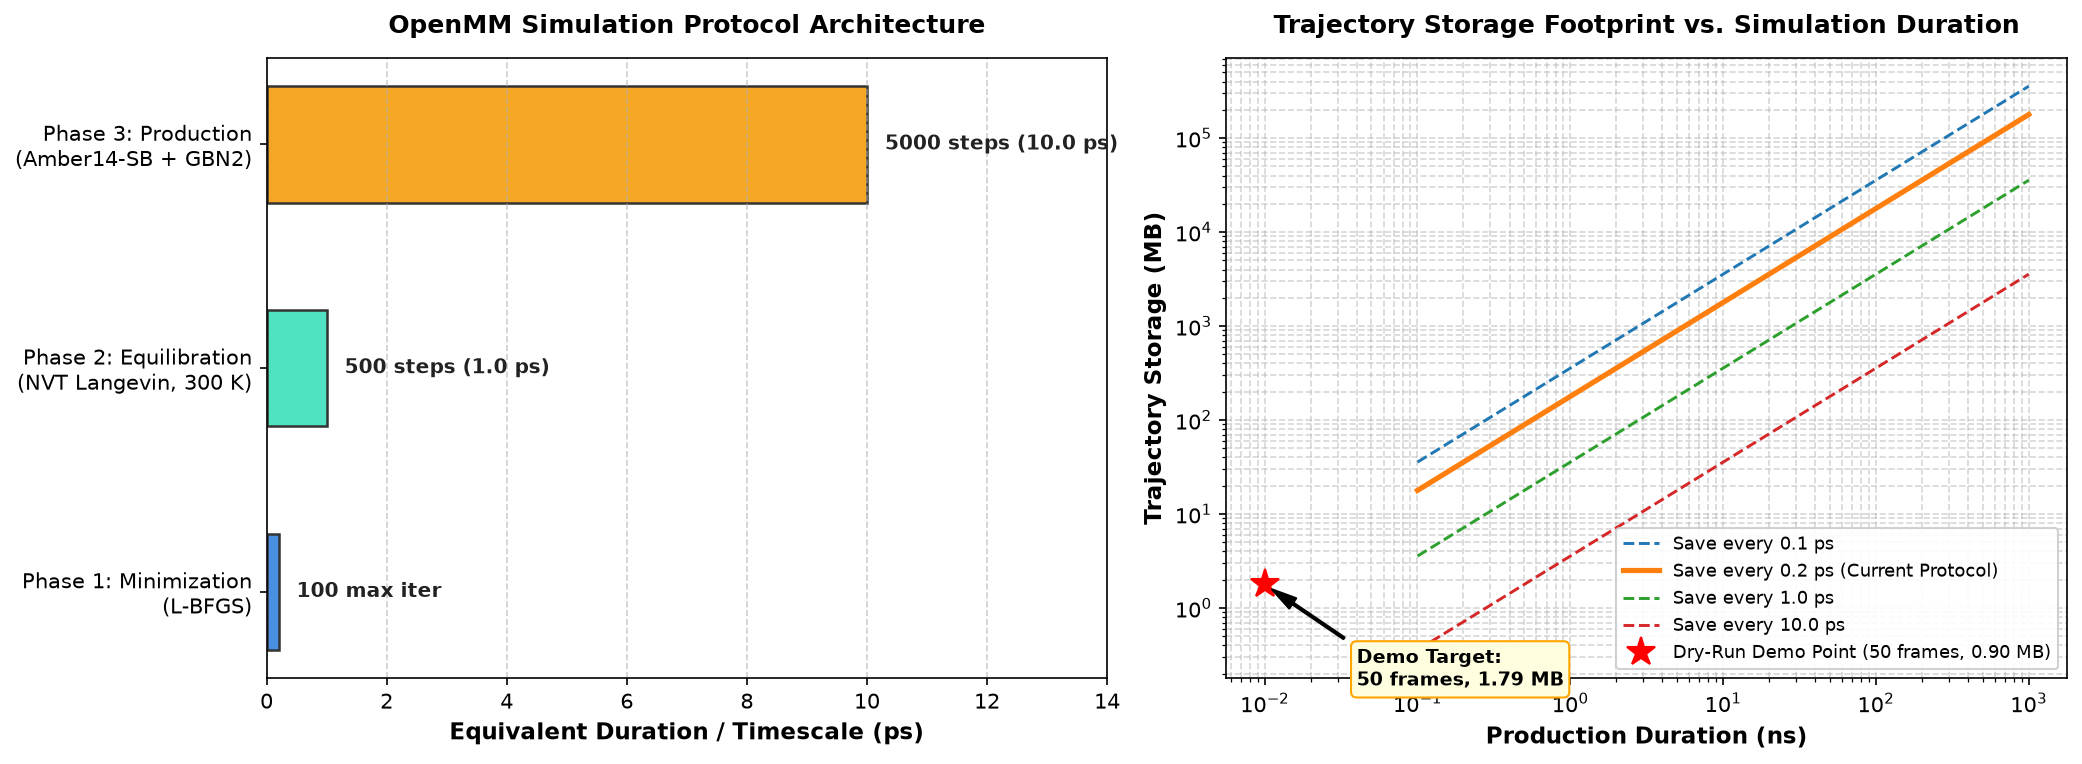

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel 1: Simulation Protocol Stages
stages = ['Phase 1: Minimization\n(L-BFGS)', 'Phase 2: Equilibration\n(NVT Langevin, 300 K)', 'Phase 3: Production\n(Amber14-SB + GBN2)']
durations_ps = [0.2, 1.0, 10.0]
colors = ['#4A90E2', '#50E3C2', '#F5A623']
bars = ax1.barh(stages, durations_ps, color=colors, edgecolor='#333', linewidth=1.2, height=0.52)

ax1.set_xlabel('Equivalent Duration / Timescale (ps)', fontsize=11, fontweight='bold')
ax1.set_title('OpenMM Simulation Protocol Architecture', fontsize=12, fontweight='bold', pad=12)
ax1.grid(axis='x', linestyle='--', alpha=0.6)

labels = ['100 max iter', '500 steps (1.0 ps)', '5000 steps (10.0 ps)']
for bar, text in zip(bars, labels):
    ax1.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, text, va='center', fontsize=9.5, fontweight='bold', color='#222')
ax1.set_xlim(0, 14)

# Panel 2: Trajectory Storage Scaling vs Simulation Duration
durations = np.logspace(-1, 3, 100) # 0.1 ns to 1000 ns
intervals_ps = [0.1, 0.2, 1.0, 10.0]
atom_count = job['estimate']['input_atom_count']

for interval in intervals_ps:
    frames = (durations * 1000.0) / interval
    bytes_mb = (frames * (12 * atom_count + 80) + 1024) / (1024 * 1024)
    line_style = '-' if interval == 0.2 else '--'
    line_width = 2.5 if interval == 0.2 else 1.4
    label = f'Save every {interval} ps' + (' (Current Protocol)' if interval == 0.2 else '')
    ax2.plot(durations, bytes_mb, label=label, linestyle=line_style, linewidth=line_width)

# Current protocol point: 10 ps = 0.01 ns
cur_dur_ns = 0.01
cur_bytes_mb = (job['estimate']['expected_frames'] * (12 * atom_count + 80) + 1024) / (1024 * 1024)
ax2.plot(cur_dur_ns, cur_bytes_mb, 'r*', markersize=14, label='Dry-Run Demo Point (50 frames, 0.90 MB)')
ax2.annotate(f"Demo Target:\n50 frames, {cur_bytes_mb:.2f} MB", xy=(cur_dur_ns, cur_bytes_mb), xytext=(0.04, 0.15),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
             fontsize=9, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='lightyellow', ec='orange'))

ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel('Production Duration (ns)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Trajectory Storage (MB)', fontsize=11, fontweight='bold')
ax2.set_title('Trajectory Storage Footprint vs. Simulation Duration', fontsize=12, fontweight='bold', pad=12)
ax2.legend(loc='lower right', fontsize=8.5, framealpha=0.9)
ax2.grid(True, which='both', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.tight_layout()
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
buf.seek(0)
display(Image(buf.read()))
plt.close(fig)

## 5. Checkpointed Execution & Provenance Tracking

MolScope guarantees reproducible simulations:
- Generates an immutable `execution_provenance.json` containing SHA-256 hashes of the topology, force field, serialized system XML, and protocol parameters.
- Writes binary checkpoints (`checkpoint.chk`) periodically.
- Interrupted or crashed runs can be resumed into immutable child segments without altering parent replica history.
- The standalone runner script can be launched independently on HPC clusters.

In [7]:
# Inspect generated launcher script
launcher_content = launcher_path.read_text(encoding="utf-8")
print(f"Generated Launcher Script ({launcher_path.name}):")
print("-" * 60)
print(launcher_content.strip())
print("-" * 60)
print(f"Executable permissions: {oct(launcher_path.stat().st_mode)[-3:]}")

print("\nStandalone Execution Commands:")
print(f"  # Review dry-run:")
print(f"  python -m molscope.simulation.openmm --plan {plan_path} --dry-run")
print(f"\n  # Execute simulation:")
print(f"  python -m molscope.simulation.openmm --plan {plan_path} --run")
print(f"\n  # Or run the generated launcher directly:")
print(f"  {launcher_path}")

Generated Launcher Script (run_openmm_plan.py):
------------------------------------------------------------
#!/usr/bin/env python3
"""Explicitly execute the reviewed OpenMM plan next to this file."""
from pathlib import Path
from molscope.openmm_plan import main

if __name__ == '__main__':
    main(['--plan', str(Path(__file__).with_name('openmm_plan.json')), '--run'])
------------------------------------------------------------
Executable permissions: 755

Standalone Execution Commands:
  # Review dry-run:
  python -m molscope.simulation.openmm --plan /Users/nirav/Docs/molscope/results/simulation_demo/sim_output/openmm_plan.json --dry-run

  # Execute simulation:
  python -m molscope.simulation.openmm --plan /Users/nirav/Docs/molscope/results/simulation_demo/sim_output/openmm_plan.json --run

  # Or run the generated launcher directly:
  /Users/nirav/Docs/molscope/results/simulation_demo/sim_output/run_openmm_plan.py


## 6. Chaining Directly into MolScope Discovery

Once the simulation completes, the prepared topology and output trajectory are loaded directly into a MolScope `Study` workspace. Here we demonstrate configuring the downstream study on our target protein with imaging and biophysical feature extraction.

In [8]:
# Instantiate study workspace and register target system
study = Study(project_id="growth_factor_discovery", out_dir=run_dir / "discovery_results")
study.add_system(
    system_id="growth_factor_hgh",
    topology=fixture_pdb,
    trajectories=[fixture_pdb],
)
study.configure_imaging(unwrap=False, center_selection="protein")
study.configure_features(
    plugins=["protein.ca_distances_contacts", "protein.secondary_structure_dssp"],
    plugin_parameters={
        "protein.ca_distances_contacts": {
            "selection": "resid 1-35",
            "contact_cutoff_angstrom": 8.0,
            "max_pairs": 3000,
        }
    }
)

spec = study.to_project_spec()
print("MolScope Study configured for downstream discovery:")
print(f"  Project ID:       {spec.project_id}")
print(f"  Systems:          {len(spec.systems)} ({spec.systems[0].system_id})")
print(f"  Active Plugins:   {list(spec.analysis.plugins)}")

# Profile target system composition
profile = study.profile_systems()[0]
print(f"\nSystem Profile for {Path(profile['topology_path']).name}:")
print(f"  Atom count:       {profile['atom_count']}")
print(f"  Residue count:    {profile['residue_count']}")
print(f"  Has protein:      {'protein' in profile['components']}")
print(f"  Has solvent:      {'solvent' in profile['components']}")
print(f"  PBC Detected:     {profile['has_periodic_cell']}")

MolScope Study configured for downstream discovery:
  Project ID:       growth_factor_discovery
  Systems:          1 (growth_factor_hgh)
  Active Plugins:   ['protein.ca_distances_contacts', 'protein.secondary_structure_dssp']

System Profile for 1A22.pdb:
  Atom count:       3113
  Residue count:    441
  Has protein:      False
  Has solvent:      False
  PBC Detected:     True


## 7. Conclusion

MolScope establishes a robust bridge from crystal/AlphaFold structures to conformational discovery:
1. **Declarative Protocols**: Specify complex molecular dynamics parameters without writing boilerplate scripts.
2. **Deterministic Dry-Run Planning**: Inspect execution requirements, frame counts, and storage footprints without importing simulation packages.
3. **Reproducibility & Provenance**: Immutable SHA-256 hashes track exact input structures, parameters, and serialized OpenMM systems.
4. **Seamless Discovery Chaining**: Direct integration into `Study` enables automatic transition from raw trajectory outputs to explainable biophysical discovery.